# Model Experiments: Kryptonite-20, -30 and -40

This notebook compares model families on the three datasets with one protocol, picks one pipeline per dataset, scores it once on a locked test set, and writes the hidden-set predictions to `hiddenlabels/` at the repository root. The helper code is in `experiment_tools.py`. Finished results are also stored in `exp_results/` (git-ignored, not needed to reproduce anything) so that an interrupted run resumes when started again; delete that folder for a fresh run.

Set the environment variable `KRYP_QUICK=1` for a dry run on 3,000 rows with small grids; its numbers mean nothing and no predictions are written.

In [1]:
import experiment_tools as et
from experiment_tools import CV, FIN, G, NS, cv_config, cv_eval, lr_post, run, sel_post

print(
    "QUICK dry run" if et.QUICK else "Full run",
    f"- {et.K}-fold CV on 80% of the rows, 20% locked test",
)

Full run - 5-fold CV on 80% of the rows, 20% locked test


## Data and Protocol

A stratified 20% of the labelled rows is a locked test set, read only at the end. The other 80% is split into five stratified folds. Every comparison and hyper-parameter choice uses these folds, and feature selection and early stopping happen inside the training folds. Models are compared by paired fold differences with Nadeau–Bengio intervals. The inputs are ±1 bits plus noise of standard deviation about 0.1, so `sign(X)` recovers the bits.

In [2]:
et.check_protocol()

n=20: 12000 labelled rows = 9600 dev (5 folds of 7680 train / 1920 validation rows) + 2400 locked; 0.496 positive
n=30: 20000 labelled rows = 16000 dev (5 folds of 12800 train / 3200 validation rows) + 4000 locked; 0.499 positive
n=40: 32000 labelled rows = 25600 dev (5 folds of 20480 train / 5120 validation rows) + 6400 locked; 0.498 positive


## Experiment 1: Polynomial Degree

The paper's baseline is quadratic logistic regression on the raw inputs (`PolynomialFeatures(2)`, `C = 0.85`). We add L1 and L2 logistic regression on monomials of degree 1 up to the largest degree that fits in memory (4, 3, 2 for n = 20, 30, 40), and the paper's own polynomial kernel at degree 10, n and 2n. On n bits there are only $2^n$ monomials, so degree n is already enough to represent every function of the bits. *Hypothesis:* the kernel value of two different rows is so small that each row is similar only to itself, so the fit memorises the training rows.

kernel tests passed
Cross-validated accuracy (mean ± sd over folds)
                                                     n = 20            n = 30            n = 40
-----------------------------------------  ----------------  ----------------  ----------------
Paper baseline (quadratic LR)                 0.544 ± 0.010     0.532 ± 0.011     0.531 ± 0.003
Best explicit LR (degree up to 4 / 3 / 2)     0.675 ± 0.017     0.582 ± 0.011     0.565 ± 0.011
    which                                  LR, L1, degree 4  LR, L1, degree 3  LR, L1, degree 2
Kernel LR, degree 10                          0.590 ± 0.010     0.549 ± 0.007     0.538 ± 0.008
    train accuracy                                    0.985             1.000             1.000
Kernel LR, degree n                           0.595 ± 0.006     0.531 ± 0.005     0.502 ± 0.000
    train accuracy                                    1.000             1.000             1.000
Kernel LR, degree 2n                          0.572 ± 0.006     0.50

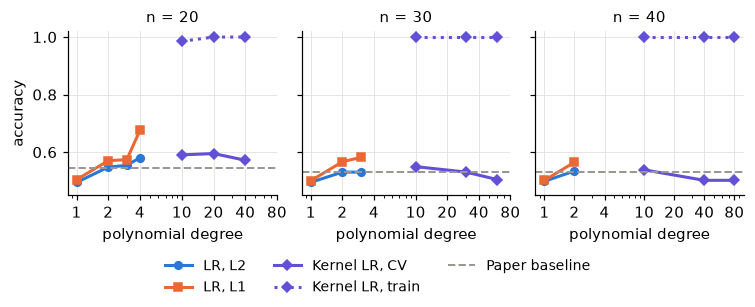

In [3]:
et.test_kernel()
for n in NS:
    cv_config(n, "BASE", "paper", "all", "deg2", dict(deg=2, C=0.85))
    for d in range(1, G["MAX_DEG"][n] + 1):
        for pen in ("l2", "l1"):
            for C in G["C_L2" if pen == "l2" else "C_L1"]:
                cv_config(n, "LR", f"lr_{pen}", "all", f"deg{d}", dict(deg=d, C=C), post=lr_post)
    for d in G["KP_DEGS"][n]:
        cv_config(
            n,
            "KPOLY",
            "kpoly",
            "all",
            f"deg{d}",
            dict(deg=d, C=G["KP_C"]),
            post=lambda m: dict(iters=m.iters_),
        )
et.table_degree()
et.fig_degree()

Is the regularisation to blame? The same kernel at degree n on fold 0 only, with `C` from 0.1 to 1000 (a larger `C` is a weaker penalty).

In [4]:
for n in NS:
    for C in (0.1, 10, 1000):
        cv_config(
            n, "KPOLYC", "kpoly", "all", f"deg{n} C check, fold 0", dict(deg=n, C=C), folds=[0]
        )
et.table_kernel_c()

Kernel LR at degree n, fold 0 only: held-out accuracy by C
                        n = 20  n = 30  n = 40
----------------------  ------  ------  ------
C = 0.1                  0.545   0.501   0.502
C = 0.85 (the paper's)   0.594   0.536   0.502
C = 10                   0.598   0.546   0.502
C = 1000                 0.603   0.550   0.502


## Experiment 2: Other Models on All Bits

The paper only tried polynomials. Trees, forests and gradient boosting are tuned by the same CV. K-means is a deliberately small baseline: each cluster predicts its training majority label, or the one-hot cluster id is the only input of a logistic regression. The MLPs use Adam with early stopping: a 2×128 network on all folds, and one 4×512 network (KryptoNet's shape) on **fold 0 only** because it is slow on a laptop CPU.

In [5]:
for n in NS:
    for d in G["DT_DEPTH"]:
        for leaf in G["DT_LEAF"]:
            cv_config(n, "TREE", "dtree", "all", "dtree", dict(max_depth=d, msl=leaf))
    for f in G["RF_MAXF"]:
        for leaf in G["RF_LEAF"]:
            cv_config(n, "TREE", "rf", "all", "rf", dict(max_features=f, msl=leaf))
    for d in G["HGB_DEPTH"]:
        cv_config(n, "TREE", "hgb", "all", "hgb", dict(max_depth=d))
    for k in G["KM_K"]:
        cv_config(n, "KM", "kmeans_major", "all", "kmeans_major", dict(k=k))
        cv_config(n, "KM", "kmeans_onehot", "all", "kmeans_onehot", dict(k=k))
    for h in G["MLP_H"]:
        for a in G["MLP_ALPHA"]:
            cv_config(
                n,
                "MLP",
                "mlp",
                "all",
                "mlp",
                dict(h=h, alpha=a),
                post=lambda m: dict(epochs=int(m.n_iter_)),
            )
    if et.RUN_KRYPTONET_SIZED:
        run(
            CV,
            f"MLP|{n}|mlp|kryptonet-sized|fold0",
            lambda: cv_eval(et.kryptonet_sized, n, folds=(0,)),
            exp="MLP",
            n=n,
            family="mlp",
            cond="all",
            sub="4x512 (fold 0 only)",
            params=dict(h=[512] * 4),
        )
et.table_families()

Cross-validated accuracy on all bits (mean ± sd over folds, best setting of each family)
                                   n = 20         n = 30         n = 40
--------------------------  -------------  -------------  -------------
Decision tree               0.690 ± 0.079  0.573 ± 0.089  0.528 ± 0.028
Random forest               0.824 ± 0.023  0.784 ± 0.028  0.786 ± 0.024
Gradient boosting           0.749 ± 0.023  0.695 ± 0.045  0.674 ± 0.053
K-means (cluster majority)  0.506 ± 0.007  0.504 ± 0.010  0.506 ± 0.006
K-means (one-hot + LR)      0.506 ± 0.007  0.505 ± 0.010  0.506 ± 0.006
MLP 2×128                   0.851 ± 0.023  0.660 ± 0.025  0.864 ± 0.041
MLP 4×512, fold 0 only              0.932          0.947          0.944
    MLP 2×128, same fold            0.848          0.643          0.899


## Experiment 3: Selecting Bits

A heuristic that runs inside every training fold: it finds the pair of bits that most strongly gates the label, scans that pair's products with up to four other bits, and keeps the bits that carry weight (details in `experiment_tools.py`). Its thresholds are choices, it has no family-wise error control, and a parity of six or more bits would be invisible to it. On shuffled labels every selected bit beyond the gate is false. The selected bits then feed a forest and a logistic regression on **all** monomials of the selected bits (a polynomial of degree k for k bits).

selector tests passed
Bit selector
                                             n = 20  n = 30  n = 40
-------------------------------------------  ------  ------  ------
Bits selected (mean over folds)                10.0    10.0    10.0
Overlap of the bits between folds (Jaccard)    1.00    1.00    1.00
Gate z-score (mean)                            12.3    15.0    18.4
Bits selected on shuffled labels                2.0     2.0     2.0
2 bits on shuffled labels = the gate pair alone, so no false bit is added.

Cross-validated accuracy (mean ± sd over folds)
                                                   n = 20           n = 30           n = 40
----------------------------------------  ---------------  ---------------  ---------------
Forest on the selected bits                 0.958 ± 0.006    0.962 ± 0.002    0.960 ± 0.002
LR on all monomials of the selected bits    0.960 ± 0.006    0.962 ± 0.002    0.960 ± 0.002
Best model on all bits                        0.851 (MLP)   0.784

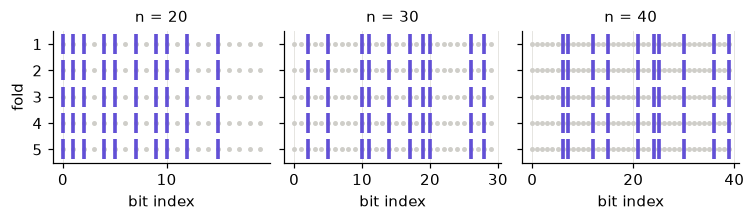

In [6]:
et.self_test()
et.run_selector_null()
for n in NS:
    for f in G["SEL_RF_MAXF"]:
        for leaf in G["SEL_RF_LEAF"]:
            cv_config(n, "SEL", "rf", "sel", "rf", dict(max_features=f, msl=leaf), post=sel_post)
    for pen in ("l2", "l1"):
        for C in G["C_L2" if pen == "l2" else "C_L1"]:
            cv_config(n, "SELPOLY", "lrfull", "sel", "lrfull", dict(pen=pen, C=C), post=sel_post)
et.table_selector()
print()
et.table_selected()
et.fig_selected_bits()

## Experiment 4: Comparing the Candidates

All candidates were scored on the same folds. The final pipeline for each n is the candidate with the highest CV mean, the paper baseline excluded; this rule was fixed before the locked test was read.

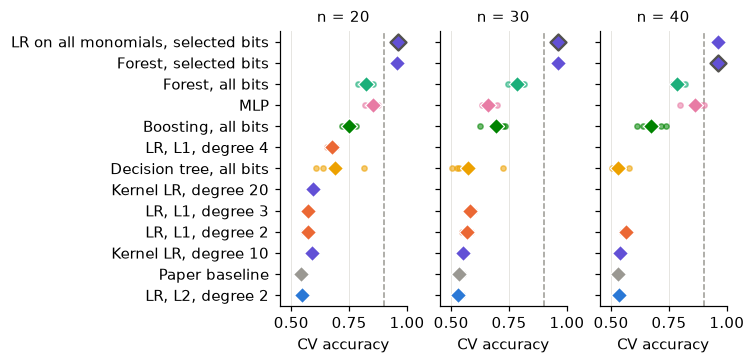

Dots: the folds. Diamond: the mean. Dashed: the 0.9 target. Dark outline: the pipeline chosen for that n. Violet: models on the selected bits.


In [7]:
FINAL = et.choose_final()
et.fig_models(FINAL)

## Experiment 5: Amount of Training Data

The top candidates are trained on nested random subsets of the training folds and scored on the held-out fold (first three folds). For logistic regression `C` multiplies the summed loss, so the same `C` penalises more strongly when there are fewer rows; `C` is scaled by (full rows / rows used) to keep the penalty per row fixed.

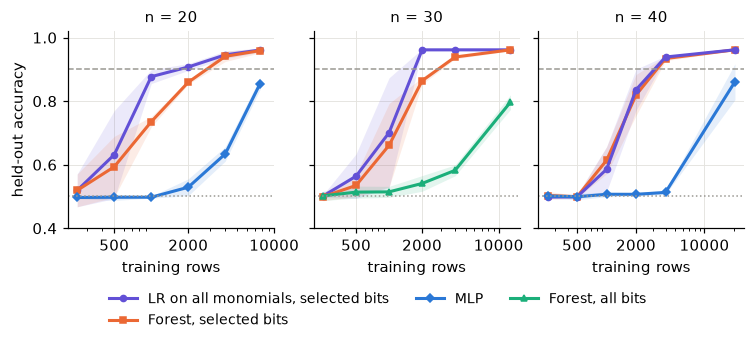

Mean over the first folds (shaded: one sd). Dashed: the 0.9 target. Dotted: chance.


In [8]:
et.fig_learning_curves(et.run_learning_curves())

## Final Pipeline and Hidden-Set Predictions

Each final pipeline is refitted on all dev rows and scored once on the locked 20%; the score is stored, so re-running reads it back. A control with shuffled training labels must give about 0.5, otherwise something leaks. The pipelines are then refitted on all labelled rows and applied to the hidden inputs; the code checks the predictions, writes `hiddenlabels/y_predicted_{20,30,40}.npy` and runs the course's `check_submission.py`. `y_predicted_40_adapt.npy` comes from the LoRA notebook.

In [9]:
et.shuffled_label_control(FINAL)
et.table_final(FINAL)
print()
et.predict_hidden(FINAL)

n = 20: LR on all monomials on selected bits (penalty l1, C 0.003)
n = 30: LR on all monomials on selected bits (penalty l1, C 0.003)
n = 40: Random forest on selected bits (max features sqrt, min leaf 1)

Final pipeline
                                                n = 20          n = 30          n = 40
--------------------------------------  --------------  --------------  --------------
CV accuracy on dev (mean ± sd)           0.960 ± 0.006   0.962 ± 0.002   0.960 ± 0.002
Locked test accuracy                             0.958           0.959           0.959
    95% interval                        [0.950, 0.966]  [0.952, 0.965]  [0.954, 0.964]
Shuffled-label control (should be 0.5)           0.504           0.501           0.499

n=20: LR on all monomials on selected bits, predicted positive rate 0.499; agrees with Random forest on selected bits on 100.0%
n=30: LR on all monomials on selected bits, predicted positive rate 0.501; agrees with Random forest on selected bits on 100.0%


## Summary

One row per approach, using the best setting of each; the groups show what each approach is allowed to see. The tables above hold the spread over folds and the paired comparisons.

In [10]:
et.table_summary(FINAL)

Summary: accuracy of each approach
                                                     n = 20  n = 30  n = 40
---------------------------------------------------  ------  ------  ------
The paper's approach: polynomials on all bits
    Quadratic LR (the paper's baseline)               0.544   0.532   0.531
    LR on all monomials up to degree 4 / 3 / 2        0.675   0.582   0.565
    Kernel LR at degree n                             0.595   0.531   0.502

Other models on all bits
    K-means                                           0.506   0.505   0.506
    Trees (best of tree, forest, boosting)            0.824   0.784   0.786
    MLP 2×128                                         0.851   0.660   0.864
    MLP 4×512, fold 0 only †                          0.932   0.947   0.944

After selecting 10 bits inside each fold
    Random forest on the selected bits                0.958   0.962   0.960
    LR on all monomials of the selected bits          0.960   0.962   0.960

Final pipeline

## Compute Used

Total model-fitting time recorded in `exp_results/`, for the environmental impact assessment.

In [11]:
CPU_WATTS = 80
GRID_G_PER_KWH = 143.96  # figures from the report
hours = sum(r.get("secs", 0) for st in (CV, et.LC, et.NUL, FIN) for r in st.rows.values()) / 3600
print(
    f"{hours:.2f} h of model fitting, about {CPU_WATTS * hours / 1000:.2f} kWh and"
    f" {CPU_WATTS * hours * GRID_G_PER_KWH / 1000:.0f} g CO2e"
)

1.27 h of model fitting, about 0.10 kWh and 15 g CO2e


**Findings**

- No model on all bits reaches 0.9 in CV: the paper's baseline scores 0.53–0.54 and the best generic model 0.78–0.86.
- The paper's kernel at degree n and 2n fits the training rows (train 1.00) but scores 0.50–0.60 held out; `C` from 0.1 to 1000 does not change this.
- The selector picks the same 10 bits in every fold. A forest and a logistic regression on those bits both reach about 0.96 in CV and on the locked test, and cannot be told apart.
- A 4×512 MLP on all bits reaches 0.93–0.95 on fold 0 without a selector; this is one fold only.
- The remaining 4% of errors is unexplained. The selector is a heuristic without a family-wise guarantee.